# 让狗走起来，要解决哪几件事？

配套《手推到狗跑》视频。同一只 Lite3（MuJoCo 仿真）、同一个关节 PD（Kp=30、Kd=1，和官方部署代码一致），换三种“上层”：

| 做法 | 上层每 12 毫秒给出 12 个关节目标角的方式 |
|---|---|
| 可皮的凑合 | 四条腿一起按正弦蹲起 |
| 可迪的手写小跑 | 对角腿轮流迈；脚的轨迹写死，用逆运动学算关节角 |
| 官方策略 | 云深处开源的 PPO 策略（45 个数进，12 个数出的小网络） |

从上往下依次运行每一格。全部跑完大约 8 分钟（侧推统计那格最慢）。

## 检查环境（先运行这一格）

报 `No module named ...` 时运行这一格就行：它会把缺的包装进你当前选中的内核。

In [1]:
# 第一次运行：检查需要的包，缺哪个就装进当前这个内核（已经装过的直接跳过）
import importlib.util
need = [p for p in ['numpy', 'matplotlib', 'mujoco'] if importlib.util.find_spec(p) is None]
if need:
    get_ipython().run_line_magic('pip', 'install ' + ' '.join(need))
    need = [p for p in need if importlib.util.find_spec(p) is None]
print('环境就绪' if not need else '还缺：' + ', '.join(need) + '（看上面 pip 的报错，或换一个 Python 内核）')


环境就绪


## 仿真代码（先运行这一格）

和同文件夹的 `walk_sim.py` 内容相同，放在这里是为了让 notebook 单独也能运行（缺的 `lite3/` 模型和 `lite3_policy.npz` 会自动从配套仓库下载）。不用读懂它，知道 `simulate(Case(...))` 会返回机身位置、倾角、着地等时间序列，`report(log)` 给出走了多远、歪了多少、翻没翻就够了。

In [2]:
"""让狗走起来，要解决哪几件事？三种“走路”放在同一套测试里比（MuJoCo，Lite3）。

    kepi   可皮的凑合：四条腿的目标角一起按正弦来回摆（没有步态时序、没有落脚点、没有平衡）
    trot   手写小跑：对角两条腿一组、轮流抬腿往前迈（有步态时序；落脚点、平衡都是固定的）
    rl     官方 RL 策略：DeepRoboticsLab/Lite3_rl_deploy 的 policy.onnx（PPO，BSD-3-Clause）

三种做法底下是同一个关节 PD（和官方部署代码一致：Kp=30、Kd=1，1000 Hz）；
上层每 12 ms 给一次 12 个关节的目标角——官方策略的输出也正是这个。
模型：DeepRoboticsLab/deep_robotics_model 的 Lite3 MJCF（BSD-3-Clause）。参数为教学设置，不代表实机。
运行环境：pip install mujoco（测试版本 3.16）；直接运行本文件 = 跑三种做法的“走 10 秒 + 侧推”测试。
"""
from dataclasses import dataclass, field
from pathlib import Path

import mujoco
import numpy as np

try:
    _HERE = Path(__file__).resolve().parent
except NameError:                  # 在 notebook 格子里运行时没有 __file__
    _HERE = Path.cwd()
# ---------------- 可视化（notebook 动画 / 3D 窗口）----------------
"""notebook 可视化公共件：MuJoCo 画面在 notebook 里放动画、几个画面并排对比、弹出 3D 窗口回放。
发布时由 make_release.py 原样并进每期的仿真文件（release.viz: true），notebook 仍然单文件能跑。

    frames = mj_frames(m, traj, cam=dict(lookat=[0, 0, 0.3], distance=1.3, azimuth=145, elevation=-14))
    show(frames)                                  # notebook 里放动画（能播放、暂停、拖动）
    show([frames_a, frames_b], titles=["只有 PD", "手推"])     # 并排对比，同步播放
    mj_view(m, traj, cam=...)                      # 弹出 MuJoCo 3D 窗口回放（鼠标拖动旋转、滚轮缩放）

traj 是 qpos 列表，或 (qpos, mocap_quat) 的列表（带会动的板子时）。
"""
import numpy as _np


def style_spec(spec):
    """画面和视频一致：渐变天空、淡色地面格子（compile 之前调用）。"""
    import mujoco
    spec.add_texture(name="sky", type=mujoco.mjtTexture.mjTEXTURE_SKYBOX, builtin=mujoco.mjtBuiltin.mjBUILTIN_GRADIENT,
                     rgb1=[0.62, 0.76, 0.92], rgb2=[0.09, 0.13, 0.23], width=512, height=3072)
    for t in spec.textures:
        if t.name == "checker":
            t.rgb1, t.rgb2 = [0.70, 0.75, 0.82], [0.86, 0.89, 0.93]
    return spec


def style_model(m):
    """机身改成中性灰（compile 之后调用），和蓝天分得开。"""
    dog = (m.geom_bodyid > 0) & (m.geom_group == 2) & (m.geom_matid < 0)
    m.geom_rgba[dog] = [0.58, 0.60, 0.64, 1]
    return m


def _set_cam(cam, spec):
    for k in ("distance", "azimuth", "elevation"):
        if k in spec:
            setattr(cam, k, spec[k])
    if "lookat" in spec:
        cam.lookat[:] = spec["lookat"]
    return cam


def _apply(d, item):
    """traj 的一项写进 MjData：qpos，或 (qpos, 板子姿态四元数)。"""
    if isinstance(item, tuple):
        d.qpos[:] = item[0]
        d.mocap_quat[0] = item[1]
    else:
        d.qpos[:] = item


def mj_frames(m, traj, cam=None, size=(480, 270), every=1, follow=None, overlay=None):
    """离屏渲染 traj（不弹窗口），返回 RGB 帧列表。
    follow=k：镜头跟着机身慢慢走（k 是每帧追上的比例，如 0.08）；overlay(scene, data)：每帧往场景里加东西（虚影、轨迹）。"""
    import mujoco
    w, h = size
    m.vis.global_.offwidth, m.vis.global_.offheight = max(m.vis.global_.offwidth, w), max(m.vis.global_.offheight, h)
    d = mujoco.MjData(m)
    r = mujoco.Renderer(m, h, w, max_geom=4000)
    c = _set_cam(mujoco.MjvCamera(), cam or {})
    opt = mujoco.MjvOption()
    opt.geomgroup[1] = 0                      # 不画碰撞网格（半透明蓝壳）
    base = _np.array(c.lookat)
    look, frames = None, []
    for i, item in enumerate(traj[::every]):
        _apply(d, item)
        mujoco.mj_forward(m, d)
        if follow:
            tgt = _np.array([d.qpos[0], d.qpos[1], base[2]])
            look = tgt if look is None else look + follow * (tgt - look)
            c.lookat[:] = look
        r.update_scene(d, c, opt)
        if overlay:
            overlay(r.scene, d)
        frames.append(r.render().copy())
    r.close()
    return frames


def caption(frames, text, color=(255, 255, 255)):
    """在每帧左上角写一行字（中文可用）。"""
    from PIL import Image, ImageDraw, ImageFont
    fo, px = None, max(14, frames[0].shape[0] // 14)
    for name in ("msyh.ttc", "simhei.ttf", "PingFang.ttc", "/System/Library/Fonts/PingFang.ttc",
                 "NotoSansCJK-Regular.ttc", "/usr/share/fonts/opentype/noto/NotoSansCJK-Regular.ttc",
                 "wqy-microhei.ttc", "/usr/share/fonts/truetype/wqy/wqy-microhei.ttc"):
        try:
            fo = ImageFont.truetype(name, px)          # Windows / macOS / Linux 常见中文字体，找到哪个用哪个
            break
        except OSError:
            continue
    fo = fo or ImageFont.load_default()
    out = []
    for f in frames:
        im = Image.fromarray(f)
        ImageDraw.Draw(im).text((10, 8), text, font=fo, fill=color, stroke_width=3, stroke_fill=(20, 24, 40))
        out.append(_np.asarray(im))
    return out


def show(frames, titles=None, fps=15, width=None):
    """在 notebook 里放动画。frames 可以是一组帧，也可以是几组帧的列表（并排同步播放，短的停在最后一帧）。
    width=None：按帧的原始像素嵌入（文件最小、不糊）；给英寸数则缩放到这个宽度。"""
    import matplotlib.pyplot as plt
    from matplotlib import animation, rcParams
    from IPython.display import HTML
    groups = frames if isinstance(frames[0], list) else [frames]
    n = max(len(g) for g in groups)
    h, w = groups[0][0].shape[:2]
    dpi = 80
    width = width or len(groups) * w / dpi * 1.01
    fig, axes = plt.subplots(1, len(groups), figsize=(width, width / len(groups) * h / w + (0.35 if titles else 0)), dpi=dpi)
    axes = _np.atleast_1d(axes)
    ims = []
    for k, (ax, g) in enumerate(zip(axes, groups)):
        ax.axis("off")
        ims.append(ax.imshow(g[0]))
        if titles:
            ax.set_title(titles[k], fontsize=11)
    fig.subplots_adjust(left=0, right=1, bottom=0, top=1 if not titles else 1 - 0.3 / fig.get_figheight(), wspace=0.02)

    def step(i):
        for im, g in zip(ims, groups):
            im.set_data(g[min(i, len(g) - 1)])
        return ims
    anim = animation.FuncAnimation(fig, step, frames=n, interval=1000 / fps)
    plt.close(fig)
    rcParams["animation.frame_format"] = "jpeg"           # 比 png 小很多，GitHub 网页上也能直接看
    rcParams["animation.embed_limit"] = 60
    return HTML(anim.to_jshtml(fps=fps, default_mode="loop"))


def mj_view(m, traj, cam=None, fps=30, repeat=3, overlay=None):
    """弹出 MuJoCo 自带的 3D 窗口回放 traj：鼠标左键拖动旋转、右键平移、滚轮缩放；播完 repeat 遍自动关闭。
    macOS 上要用 mjpython 运行；远程服务器、没有显示器的环境请用 show()。"""
    import time
    import mujoco
    import mujoco.viewer
    d = mujoco.MjData(m)
    with mujoco.viewer.launch_passive(m, d) as v:
        _set_cam(v.cam, cam or {})
        v.opt.geomgroup[1] = 0
        for _ in range(repeat):
            for item in traj:
                if not v.is_running():
                    return
                _apply(d, item)
                mujoco.mj_forward(m, d)
                if overlay:
                    with v.lock():
                        v.user_scn.ngeom = 0
                        overlay(v.user_scn, d)
                v.sync()
                time.sleep(1 / fps)
            time.sleep(1.0)
# 发布包里模型放在同文件夹的 lite3/；找不到时退回作者本地的模型路径
MJCF = next((p for p in [_HERE / "lite3", _HERE.parents[1] / "assets" / "deep_robotics_model-main" / "Lite3" / "mjcf"]
             if (p / "Lite3.xml").exists()), _HERE / "lite3")
POLICY = _HERE / "lite3_policy.npz"

# ---------------- 和官方部署代码一致的常数（Lite3_rl_deploy/run_policy） ----------------
DT = 0.001                                      # 物理步长 1 ms
DECIM = 12                                      # 上层每 12 步（12 ms）给一次目标角
KP, KD, TAU_MAX = 30.0, 1.0, 30.0               # 关节 PD
Q0 = np.tile([0.0, -0.65, 1.30], 4)             # 默认站姿：每条腿 [髋侧摆, 髋前后, 膝]，腿序 FL FR HL HR
ACT_SCALE = np.tile([0.125, 0.25, 0.25], 4)     # 策略输出 × 这个 = 目标角相对站姿的偏移
CMD_MAX = 0.8                                   # 速度指令上限（m/s、rad/s），训练时见过的范围
LEGS = ["FL", "FR", "HL", "HR"]


REPO = ["https://gitee.com/nononodoubt/shoutui-daogoupao/raw/main/四足/让狗走起来/",
        "https://fastly.jsdelivr.net/gh/NONONODOUBT/shoutui-daogoupao@main/四足/让狗走起来/",
        "https://raw.githubusercontent.com/NONONODOUBT/shoutui-daogoupao/main/四足/让狗走起来/"]
LITE3_FILES = ["lite3/Lite3.xml", "lite3/LICENSE.txt"] + [f"lite3/meshes/{n}.STL" for n in ("torso", "hip", "thigh", "shank")]


def download(files, dst):
    """只拿到 notebook、旁边缺文件时，从配套仓库下载（国内先走 Gitee）。files 是相对仓库这一期文件夹的路径。"""
    from urllib.parse import quote
    from urllib.request import urlopen
    for base in REPO:
        try:
            for f in files:
                data = urlopen(quote(base + f, safe=":/@"), timeout=30).read()
                (dst / f).parent.mkdir(parents=True, exist_ok=True)
                (dst / f).write_bytes(data)
            print(f"已下载 {', '.join(Path(f).name for f in files)} 到 {dst}")
            return
        except OSError as e:
            print(f"从 {base.split('/')[2]} 下载失败（{e}），换一个地址")
    raise FileNotFoundError(f"缺少 {files}：请从配套仓库下载，放到 {dst}")


def load_model():
    """MuJoCo 在 Windows 上打不开中文路径：自己读 XML 和网格，以内容形式传进去。"""
    if not (MJCF / "Lite3.xml").exists():
        download(LITE3_FILES, MJCF.parent)
    xml = (MJCF / "Lite3.xml").read_text(encoding="utf-8")
    assets = {f"./meshes/{p.name}": p.read_bytes() for p in (MJCF / "meshes").iterdir()}
    spec = mujoco.MjSpec.from_string(xml, assets)
    spec.assets = {k[2:]: v for k, v in assets.items()}
    spec.add_texture(name="sky", type=mujoco.mjtTexture.mjTEXTURE_SKYBOX, builtin=mujoco.mjtBuiltin.mjBUILTIN_GRADIENT,
                     rgb1=[0.62, 0.76, 0.92], rgb2=[0.09, 0.13, 0.23], width=512, height=3072)
    for t in spec.textures:
        if t.name == "checker":
            t.rgb1, t.rgb2 = [0.70, 0.75, 0.82], [0.86, 0.89, 0.93]
    m = spec.compile()
    m.opt.timestep = DT
    m.vis.global_.offwidth, m.vis.global_.offheight = 1920, 1080
    vis = (m.geom_bodyid > 0) & (m.geom_group == 2) & (m.geom_matid < 0)
    m.geom_rgba[vis] = [0.58, 0.60, 0.64, 1]
    return m


# ---------------- 上层 1：官方 RL 策略 ----------------
class RLPolicy:
    """45 维观测 → 12 维动作的小网络（45→512→256→128→12，ELU）。权重由 onnx_to_npz.py 从 policy.onnx 读出。"""

    def __init__(self, path=POLICY):
        if not Path(path).exists():
            download([Path(path).name], Path(path).parent)
        w = np.load(path)
        self.layers = [(w[f"mlp_{i}_weight"], w[f"mlp_{i}_bias"]) for i in (0, 2, 4, 6)]
        self.last = np.zeros(12)

    def obs(self, d, cmd):
        """观测（顺序和缩放与官方 runner 一致）：机身角速度×0.25、重力在机身里的方向、速度指令、
        关节角 − 站姿、关节角速度×0.05、上一次的动作。注意：没有“机身速度”，它得自己从别的量里猜。"""
        R = np.zeros(9)
        mujoco.mju_quat2Mat(R, d.qpos[3:7])
        grav = R.reshape(3, 3).T @ np.array([0, 0, -1.0])
        return np.concatenate([d.qvel[3:6] * 0.25, grav, np.clip(cmd, -CMD_MAX, CMD_MAX),
                               d.qpos[7:19] - Q0, d.qvel[6:18] * 0.05, self.last])

    def __call__(self, d, t, cmd):
        x = self.obs(d, cmd)
        for i, (W, b) in enumerate(self.layers):
            x = W @ x + b
            if i < 3:
                x = np.where(x > 0, x, np.expm1(np.minimum(x, 0)))      # ELU
        self.last = x
        return Q0 + x * ACT_SCALE


# ---------------- 上层 2、3：手写 ----------------
def kepi_targets(amp=0.2, freq=2.5):
    """可皮：四条腿一起蹲起——髋前后和膝按同一个正弦摆（膝摆两倍，脚大致在髋正下方上下动）。"""
    def f(d, t, cmd):
        s = amp * np.sin(2 * np.pi * freq * t)
        return Q0 + np.tile([0.0, -s, 2 * s], 4)
    return f


L1, L2 = 0.20, 0.21012          # 大腿、小腿长（m）
H0 = 0.3265                     # 默认站姿下脚在髋下方的深度（m）


def leg_ik(x, z):
    """脚在髋坐标系里的位置（x 往前、z 往上，单位 m）→ (髋前后, 膝)。
    正运动学：x = L1·sin(髋) + L2·sin(髋+膝)，z = −L1·cos(髋) − L2·cos(髋+膝)。"""
    D2 = x * x + z * z
    knee = np.arccos(np.clip((D2 - L1 ** 2 - L2 ** 2) / (2 * L1 * L2), -1, 1))
    hip = np.arctan2(x, -z) - np.arctan2(L2 * np.sin(knee), L1 + L2 * np.cos(knee))
    return hip, knee


def trot_targets(freq=3.0, step=0.30, lift=0.16, duty=0.5, height=0.23):
    """手写小跑：FL+HR 一组、FR+HL 一组，相位差半个周期。
    每只脚的轨迹是写死的：着地时贴着地面从前往后匀速蹬 step 米，离地时抬高 lift 米再迈回前面；
    再用 leg_ik 反解出关节角。脚落在哪儿、身子歪了怎么办——都没写，所以一推就……"""
    phase = np.array([0.0, 0.5, 0.5, 0.0])
    def f(d, t, cmd):
        q = Q0.copy()
        p = (freq * t + phase) % 1.0
        stance = p < duty
        u = np.where(stance, p / duty, (p - duty) / (1 - duty))        # 本阶段进度 0→1
        x = np.where(stance, step / 2 - step * u, -step / 2 * np.cos(np.pi * u))
        z = -height + np.where(stance, 0.0, lift * np.sin(np.pi * u))
        hip, knee = leg_ik(x, z)
        q[1::3], q[2::3] = hip, knee
        return q
    return f


# ---------------- 测试 ----------------
@dataclass
class Case:
    mode: str = "rl"                     # kepi / trot / rl
    T: float = 10.0
    cmd: tuple = (0.5, 0.0, 0.0)         # 速度指令（只有 rl 用）：前进 m/s、侧移 m/s、转向 rad/s
    pushes: list = field(default_factory=list)   # [(开始秒, 侧向力 N, 持续秒)]
    settle: float = 0.5                  # 开始前先按站姿站稳
    kw: dict = field(default_factory=dict)       # 传给手写步态的参数
    upper: object = None                 # 自定义上层（工厂函数，返回 f(d, t, cmd) → 12 个目标角），给 mode="custom" 用


def make_upper(c):
    if c.mode == "custom":
        return c.upper()
    return {"rl": lambda: RLPolicy(), "kepi": lambda: kepi_targets(**c.kw),
            "trot": lambda: trot_targets(**c.kw)}[c.mode]()


def simulate(c: Case, m=None, traj=None, fps=30):
    """返回日志：t、机身位置 xyz、横滚/俯仰/偏航、四只脚是否着地、脚相对机身的左右位置 foot_y（按机身朝向算，m）、
    关节跟踪误差 track（目标角 − 实际角的均方根，rad）；traj 给列表时按 fps 存 qpos（渲染用）。"""
    m = m or load_model()
    d = mujoco.MjData(m)
    d.qpos[2] = 0.36
    d.qpos[3:7] = [1, 0, 0, 0]
    d.qpos[7:19] = Q0
    upper = make_upper(c)
    torso = mujoco.mj_name2id(m, mujoco.mjtObj.mjOBJ_BODY, "TORSO")
    feet = [mujoco.mj_name2id(m, mujoco.mjtObj.mjOBJ_GEOM, f"{l}_SHANK_collision") for l in LEGS]   # 小腿碰撞网格包住了脚，着地的是它
    floor = mujoco.mj_name2id(m, mujoco.mjtObj.mjOBJ_GEOM, "floor")
    n_settle, n = int(c.settle / DT), int((c.settle + c.T) / DT)
    log = {k: [] for k in ("t", "x", "y", "z", "roll", "pitch", "yaw", "contact", "foot_x", "foot_y", "track")}
    foot_b = [mujoco.mj_name2id(m, mujoco.mjtObj.mjOBJ_BODY, f"{l}_FOOT") for l in LEGS]
    q_des = Q0.copy()
    every = max(1, int(round(1 / (fps * DT))))
    for k in range(n):
        t = (k - n_settle) * DT
        if k >= n_settle and (k - n_settle) % DECIM == 0:
            q_des = upper(d, t, np.array(c.cmd))
        d.xfrc_applied[torso] = 0
        for t0, fy, dur in c.pushes:
            if t0 <= t < t0 + dur:
                d.xfrc_applied[torso, 1] = fy
        tau = KP * (q_des - d.qpos[7:19]) - KD * d.qvel[6:18]
        d.ctrl[:] = np.clip(tau, -TAU_MAX, TAU_MAX)
        mujoco.mj_step(m, d)
        if k >= n_settle and (k - n_settle) % 10 == 0:              # 日志 100 Hz
            w, x, y, z = d.qpos[3:7]
            log["t"].append(t)
            log["x"].append(d.qpos[0]); log["y"].append(d.qpos[1]); log["z"].append(d.qpos[2])
            log["roll"].append(np.arctan2(2 * (w * x + y * z), 1 - 2 * (x * x + y * y)))
            log["pitch"].append(np.arcsin(np.clip(2 * (w * y - z * x), -1, 1)))
            log["yaw"].append(np.arctan2(2 * (w * z + x * y), 1 - 2 * (y * y + z * z)))
            on = [False] * 4
            for ci in range(d.ncon):
                g = {d.contact[ci].geom1, d.contact[ci].geom2}
                for i, fg in enumerate(feet):
                    if fg in g and floor in g:
                        on[i] = True
            log["contact"].append(on)
            yaw = log["yaw"][-1]
            side = np.array([-np.sin(yaw), np.cos(yaw)])                  # 机身朝向的“左”方向（水平面内）
            fwd = np.array([np.cos(yaw), np.sin(yaw)])
            log["foot_x"].append([float((d.xpos[b][:2] - d.qpos[:2]) @ fwd) for b in foot_b])
            log["foot_y"].append([float((d.xpos[b][:2] - d.qpos[:2]) @ side) for b in foot_b])
            log["track"].append(float(np.sqrt(np.mean((q_des - d.qpos[7:19]) ** 2))))
        if traj is not None and k % every == 0:
            traj.append(d.qpos.copy())
    return {k: np.array(v) for k, v in log.items()}


def fell(log):
    tilt = np.hypot(log["roll"], log["pitch"])
    bad = np.nonzero((tilt > np.radians(60)) | (log["z"] < 0.12))[0]
    return float(log["t"][bad[0]]) if len(bad) else None


def report(log):
    t_fall = fell(log)
    end = len(log["t"]) - 1 if t_fall is None else int(np.searchsorted(log["t"], t_fall))
    return {"前进_m": round(float(log["x"][end] - log["x"][0]), 2),
            "侧偏_m": round(float(log["y"][end] - log["y"][0]), 2),
            "偏航_deg": round(float(np.degrees(np.unwrap(log["yaw"])[end] - log["yaw"][0])), 1),   # 展开，转过半圈也不会绕回
            "最大倾角_deg": round(float(np.degrees(np.hypot(log["roll"], log["pitch"])[:end + 1].max())), 1),
            "翻倒时刻_s": t_fall}


# ---------------- 看画面 ----------------
CAM = dict(lookat=[0, 0, 0.28], distance=1.8, azimuth=120, elevation=-12)


def movie(c: Case, m=None, title=None, size=(400, 225), fps=10):
    """跑一遍 c，渲染成帧（不弹窗口，镜头跟着狗走）；左上角写 title 和结果。"""
    m = m or load_model()
    traj = []
    r = report(simulate(c, m, traj=traj, fps=fps))
    frames = mj_frames(m, traj, cam=CAM, size=size, follow=0.25)
    tag = f"{r['翻倒时刻_s']:.1f} 秒翻了！" if r["翻倒时刻_s"] else f"走了 {r['前进_m']} m"
    return caption(frames, f"{title}　{tag}" if title else tag)


def show_cases(cases, m=None):
    """几种情况并排同步播放：cases = {"可皮的凑合": Case(mode="kepi"), "官方策略": Case(mode="rl")}。"""
    m = m or load_model()
    return show([movie(c, m, name) for name, c in cases.items()], fps=10)


def view_case(c: Case):
    """弹出 MuJoCo 的 3D 窗口看一种走法（鼠标拖动旋转、滚轮缩放，双击机身可以让镜头跟着它）。macOS 用 mjpython 运行。"""
    m = load_model()
    traj = []
    simulate(c, m, traj=traj, fps=30)
    mj_view(m, traj, cam=CAM, fps=30)


PUSHES = [(5.0, 80.0, 0.2), (7.5, -80.0, 0.2)]      # 走到第 5 秒从左边推一下、7.5 秒从右边推一下（80 N 推 0.2 s）


In [3]:
from walk_sim import *

## 准备工作（运行一次即可）

- 设置中文字体（不设的话图里的中文会变成方框）；
- `m = load_model()`：读入 Lite3 模型；
- `tilt(log)`：机身相对水平歪了多少度；`contact_plot(log)`：画四只脚的着地时序。

In [4]:
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei', 'SimHei', 'Noto Sans CJK SC', 'PingFang SC', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False

m = load_model()


def tilt(log):
    return np.degrees(np.hypot(log['roll'], log['pitch']))


def contact_plot(log, t0=3.0, dur=1.2, title=''):
    sel = (log['t'] >= t0) & (log['t'] < t0 + dur)
    t, c = log['t'][sel], log['contact'][sel]
    plt.figure(figsize=(8, 2.2))
    for i, (name, col) in enumerate(zip(['左前', '右前', '左后', '右后'], ['gold', 'tab:blue', 'tab:blue', 'gold'])):
        plt.fill_between(t, 3 - i - 0.35, 3 - i + 0.35, where=c[:, i], color=col, step='post')
    plt.yticks([3, 2, 1, 0], ['左前', '右前', '左后', '右后']); plt.xlabel('时间 / 秒'); plt.title(title); plt.show()
    cc = log['contact'][log['t'] > 2.0]               # 同起同落按第 2 秒以后整段算（和视频一致），图只画一小段
    d = ((cc[:, 0] == cc[:, 3]).mean() + (cc[:, 1] == cc[:, 2]).mean()) / 2
    print(f'对角两条腿同起同落：{d * 100:.0f}%')

## 1. 三种走法：走 10 秒

`report` 给出：往前走了多远、往旁边偏了多少、转了多少度、机身最大倾角、什么时候翻的（没翻是 None）。
注意“关节跟踪误差”：可皮的最小，却最先翻——关节跟得准，只是四件事里的一件。

In [5]:
for mode in ['kepi', 'trot', 'rl']:
    log = simulate(Case(mode=mode), m)
    print(f"{mode:5s}", report(log), f"  关节跟踪误差 {np.median(log['track']):.2f} rad")

kepi  {'前进_m': -0.23, '侧偏_m': 0.0, '偏航_deg': 0.4, '最大倾角_deg': 60.7, '翻倒时刻_s': 3.73}   关节跟踪误差 0.10 rad


trot  {'前进_m': 7.02, '侧偏_m': 0.12, '偏航_deg': 5.6, '最大倾角_deg': 11.5, '翻倒时刻_s': None}   关节跟踪误差 0.31 rad


rl    {'前进_m': 4.83, '侧偏_m': -0.25, '偏航_deg': 4.1, '最大倾角_deg': 3.7, '翻倒时刻_s': None}   关节跟踪误差 0.13 rad


三种走法并排同步播放（可以暂停、拖动）：

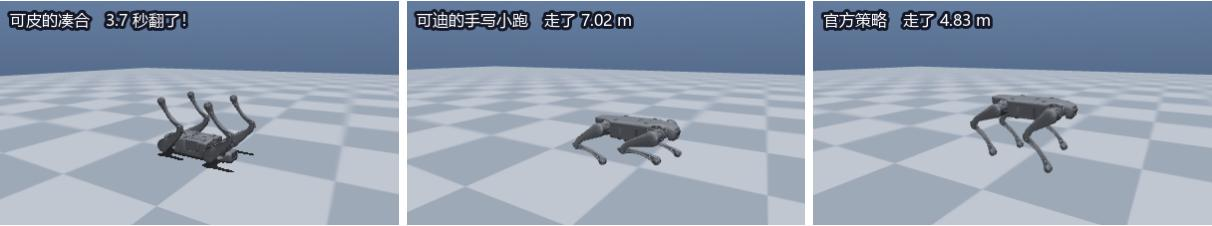

↑ 动画中的一帧。自己运行这一格，会播放完整动画（可以暂停、拖动）。


In [6]:
show_cases({'可皮的凑合': Case(mode='kepi'), '可迪的手写小跑': Case(mode='trot'), '官方策略': Case(mode='rl')}, m)

想自己转着看：运行 `view_case(Case(mode='rl'))`，或者在终端里 `python walk_sim.py --view`，会弹出 MuJoCo 的 3D 窗口（鼠标拖动旋转、滚轮缩放；macOS 用 `mjpython`）。

## 2. 着地时序：官方策略自己学出了小跑

没有人告诉官方策略要对角迈腿。看看它的四只脚什么时候着地。

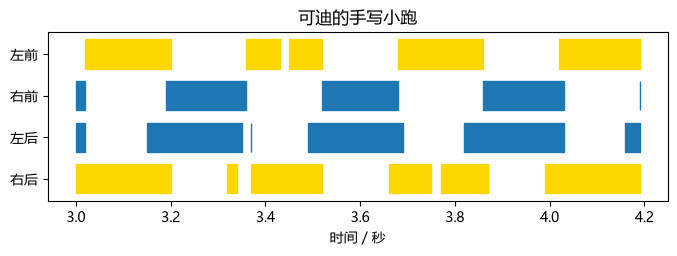

对角两条腿同起同落：87%


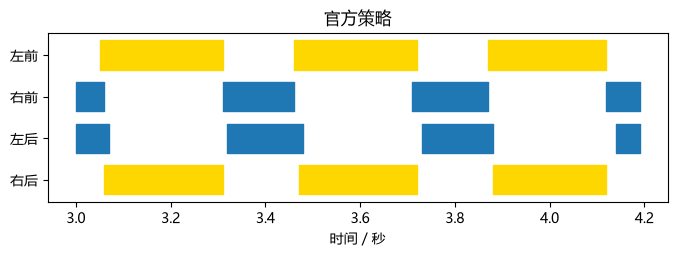

对角两条腿同起同落：96%


In [7]:
contact_plot(simulate(Case(mode='trot'), m), title='可迪的手写小跑')
contact_plot(simulate(Case(mode='rl'), m), title='官方策略')

## 3. 侧推 110 牛

走到第 5 秒，从左边推 0.2 秒。橙色竖线是推的时刻。

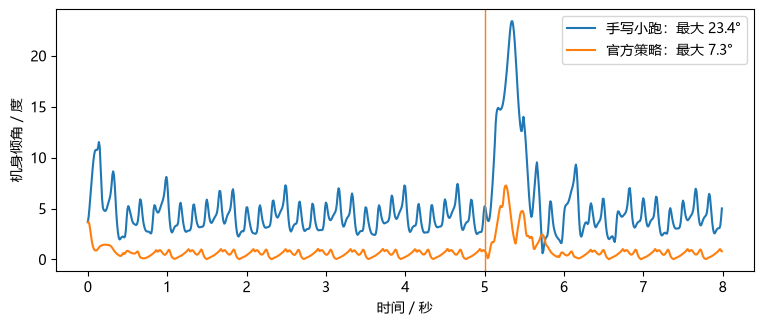

In [8]:
plt.figure(figsize=(9, 3.4))
for mode, name in [('trot', '手写小跑'), ('rl', '官方策略')]:
    log = simulate(Case(mode=mode, T=8, pushes=[(5.0, 110.0, 0.2)]), m)
    plt.plot(log['t'], tilt(log), label=f"{name}：最大 {report(log)['最大倾角_deg']}°")
plt.axvline(5.0, color='tab:orange', lw=1); plt.xlabel('时间 / 秒'); plt.ylabel('机身倾角 / 度'); plt.legend(); plt.show()

同一推，看两只狗（第 5 秒从左边推）：

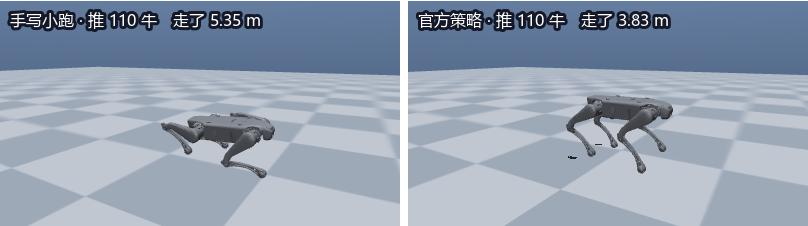

↑ 动画中的一帧。自己运行这一格，会播放完整动画（可以暂停、拖动）。


In [9]:
show_cases({'手写小跑 · 推 110 牛': Case(mode='trot', T=8, pushes=[(5.0, 110.0, 0.2)]),
            '官方策略 · 推 110 牛': Case(mode='rl', T=8, pushes=[(5.0, 110.0, 0.2)])}, m)

## 4. 悬崖式失败

每种推力在 6 个不同时机各推一次，统计扛住几次、最大倾角的中位数。这一格要跑 72 次仿真，大约 5 分钟。

60 牛：手写扛住 6/6（13.7°）   官方扛住 6/6（3.8°）


80 牛：手写扛住 6/6（16.2°）   官方扛住 6/6（5.2°）


100 牛：手写扛住 6/6（20.9°）   官方扛住 6/6（6.8°）


110 牛：手写扛住 6/6（24.3°）   官方扛住 6/6（7.2°）


120 牛：手写扛住 5/6（30.0°）   官方扛住 4/6（8.8°）


130 牛：手写扛住 4/6（39.4°）   官方扛住 0/6（60.8°）


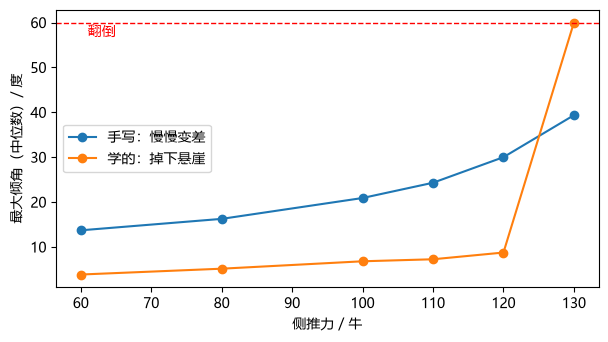

In [10]:
forces = [60, 80, 100, 110, 120, 130]
stats = {'trot': [], 'rl': []}
for F in forces:
    for mode in stats:
        rs = [report(simulate(Case(mode=mode, T=8, pushes=[(t0, F, 0.2)]), m)) for t0 in [5.0, 5.06, 5.12, 5.18, 5.24, 5.30]]
        ok = sum(r['翻倒时刻_s'] is None for r in rs)
        stats[mode].append((ok, np.median([r['最大倾角_deg'] for r in rs])))
    print(f"{F} 牛：手写扛住 {stats['trot'][-1][0]}/6（{stats['trot'][-1][1]:.1f}°）   官方扛住 {stats['rl'][-1][0]}/6（{stats['rl'][-1][1]:.1f}°）")
plt.figure(figsize=(7, 3.6))
for mode, name in [('trot', '手写：慢慢变差'), ('rl', '学的：掉下悬崖')]:
    plt.plot(forces, [min(v, 60) for _, v in stats[mode]], 'o-', label=name)
plt.axhline(60, color='r', ls='--', lw=1); plt.text(61, 57, '翻倒', color='r')
plt.xlabel('侧推力 / 牛'); plt.ylabel('最大倾角（中位数）/ 度'); plt.legend(); plt.show()

推到训练范围外的 130 牛，看看“悬崖”长什么样（第 5.06 秒推，上面统计里的一个时机；换成 5.0 秒两只都会翻，可以自己试）：

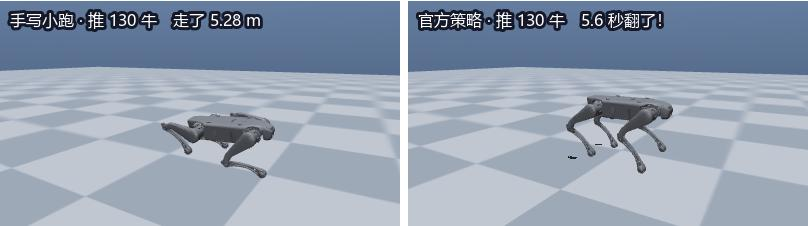

↑ 动画中的一帧。自己运行这一格，会播放完整动画（可以暂停、拖动）。


In [11]:
show_cases({'手写小跑 · 推 130 牛': Case(mode='trot', T=8, pushes=[(5.06, 130.0, 0.2)]),
            '官方策略 · 推 130 牛': Case(mode='rl', T=8, pushes=[(5.06, 130.0, 0.2)])}, m)

## 5. 落脚点：走得越快，脚落得越靠前

`foot_x` 是脚相对机身的前后位置；取每次刚着地的那一刻，减去髋的位置（±0.1745 m）。

In [12]:
HX = np.array([0.1745, 0.1745, -0.1745, -0.1745])
for v in [0.5, 0.8]:
    log = simulate(Case(mode='rl', T=6, cmd=(v, 0, 0)), m)
    t, c, fx = log['t'], log['contact'].astype(int), log['foot_x'] - HX
    td = [fx[k, i] for k in range(1, len(t)) for i in range(4) if c[k, i] and not c[k - 1, i] and t[k] > 2]
    print(f'指令 {v} m/s：实际 {report(log)["前进_m"] / 6:.2f} m/s，着地时脚在髋前方 {100 * np.mean(td):.1f} cm')

指令 0.5 m/s：实际 0.48 m/s，着地时脚在髋前方 3.6 cm


指令 0.8 m/s：实际 0.82 m/s，着地时脚在髋前方 5.8 cm


## 作业

下面三格要你自己改、自己跑。

In [ ]:
# 作业 1：改可迪手写小跑的参数，看看最快能走多快、代价是什么（机身倾角？会不会翻？）。
# trot_targets(freq=3.0, step=0.30, lift=0.16, duty=0.5, height=0.23)
log = simulate(Case(mode='trot', kw=dict(freq=3.0, step=0.30)), m)
print(report(log))

In [ ]:
# 作业 2：给官方策略不同的速度指令，找出它从“站着不动”到“开始迈腿”的那个速度。
for v in [0.2, 0.3]:
    print(v, report(simulate(Case(mode='rl', T=5, cmd=(v, 0, 0)), m)))

In [ ]:
# 作业 3（思考题）：想让学出来的策略扛住 130 牛，训练的时候要改什么？会不会有代价？
# 答案在视频的置顶评论里。
